# 06 - Stress-testing the pedestrian finding against a real detector

Notebook `05_trainval_motion_ablation.ipynb` found radar's cleanest contribution to be pedestrian motion counting:
with the model's object tokens placed using **ground-truth** boxes, every radar-containing model beat the majority
baseline on "how many pedestrians are moving," while camera alone did not.

That result has a real weakness: ground-truth boxes are not available at the moment a deployed system would need to
answer a question -- only the project's own trained detector's predictions are. This notebook replaces the oracle
boxes with the detector's real, noisy predictions and asks a direct question: **does the pedestrian finding
survive?**

**What we measured about the detector first, since it tells us what to expect:** sampled 500 validation keyframes
and compared its predictions to ground truth, per class. At its original operating point (keeping any detection
scoring above 0.3):

- car: catches 37% of real cars, and 57% of what it reports is a real nearby car (precision).
- pedestrian: catches only 11% of real pedestrians, and only 49% of what it reports is real.

Pedestrians are the weaker class by a wide margin -- exactly where the pedestrian-counting finding would be most at
risk.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path(r"D:\radar-bev-llm")
sys.path.insert(0, str(ROOT / "code" / "radar"))

NAMES = ["blind_trainval_motionqa", "camera_trainval_motionqa", "radar_trainval_motionqa",
         "motion_only_trainval_motionqa", "radar_obj_trainval_motionqa",
         "radar_obj_trainval_motionqa_det", "radar_obj_trainval_motionqa_det_balanced",
         "radar_obj_trainval_motionqa_det2"]
LABELS = {"blind_trainval_motionqa": "blind", "camera_trainval_motionqa": "camera alone",
          "radar_trainval_motionqa": "dense radar\nalone", "motion_only_trainval_motionqa": "object tokens\nalone (oracle)",
          "radar_obj_trainval_motionqa": "radar+object\n(ORACLE boxes)",
          "radar_obj_trainval_motionqa_det": "detected, 0.3 thr\nunbalanced slots",
          "radar_obj_trainval_motionqa_det_balanced": "detected, 0.3 thr\nbalanced slots",
          "radar_obj_trainval_motionqa_det2": "detected, 0.15 thr\nbalanced slots"}

R = {}
for n in NAMES:
    p = ROOT / "outputs" / f"qa_{n}.json"
    if p.exists():
        R[n] = json.load(open(p, encoding="utf-8"))
    else:
        print("MISSING:", p)

MAJ = dict(moving_count_car=0.195, moving_count_pedestrian=0.34, top_speed_car=0.345)
print("loaded", len(R), "models")

loaded 8 models


## Part 1: the first real-detector attempt

Swapping in the detector's raw predictions (keeping the original object-token code, which picks whichever 8 objects
are nearest the car regardless of class) gave a real but incomplete answer: most of the story survived, but the
pedestrian number specifically weakened.

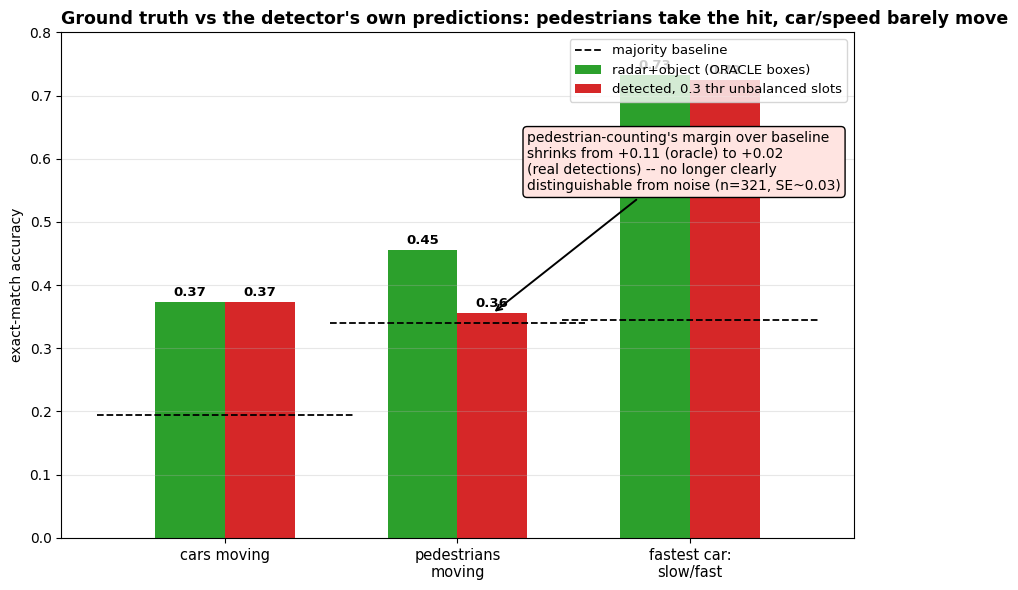

gap, oracle: 0.075
gap, detected: 0.043


In [2]:
types = ["moving_count_car", "moving_count_pedestrian", "top_speed_car"]
type_labels = ["cars moving", "pedestrians\nmoving", "fastest car:\nslow/fast"]
pair = ["radar_obj_trainval_motionqa", "radar_obj_trainval_motionqa_det"]

fig, ax = plt.subplots(figsize=(9, 6))
x = np.arange(3)
w = 0.3
for i, n in enumerate(pair):
    vals = [R[n]["per_type"][t] for t in types]
    ax.bar(x + (i - 0.5) * w, vals, w, label=LABELS[n].replace("\n", " "), color=["tab:green", "tab:red"][i])
    for xi, v in zip(x + (i - 0.5) * w, vals):
        ax.text(xi, v + 0.01, f"{v:.2f}", ha="center", fontsize=9.5, fontweight="bold")
for xi, t in zip(x, types):
    ax.plot([xi - 0.55, xi + 0.55], [MAJ[t], MAJ[t]], "k--", lw=1.3)
ax.plot([], [], "k--", lw=1.3, label="majority baseline")
ax.set_xticks(x); ax.set_xticklabels(type_labels, fontsize=10.5)
ax.set_ylabel("exact-match accuracy")
ax.set_ylim(0, 0.8)
ax.set_title("Ground truth vs the detector's own predictions: pedestrians take the hit, car/speed barely move", fontsize=12.5, fontweight="bold", loc="left")
ax.legend(loc="upper right", fontsize=9.5)
ax.grid(alpha=0.3, axis="y")
ax.annotate("pedestrian-counting's margin over baseline\nshrinks from +0.11 (oracle) to +0.02\n(real detections) -- no longer clearly\ndistinguishable from noise (n=321, SE~0.03)",
            xy=(1 + 0.15, R["radar_obj_trainval_motionqa_det"]["per_type"]["moving_count_pedestrian"]),
            xytext=(1.3, 0.55), fontsize=10, bbox=dict(boxstyle="round", fc="mistyrose", ec="k"), arrowprops=dict(arrowstyle="->", lw=1.4))
plt.tight_layout()
plt.show()

print("gap, oracle:", round(R["radar_obj_trainval_motionqa"]["val_acc"] - R["radar_obj_trainval_motionqa"]["val_acc_shuffled_radar"], 3))
print("gap, detected:", round(R["radar_obj_trainval_motionqa_det"]["val_acc"] - R["radar_obj_trainval_motionqa_det"]["val_acc_shuffled_radar"], 3))

## Part 2: two cheap fixes, tested in isolation

Two plausible, cheap-to-test explanations for the pedestrian drop:

1. **Slot crowding.** The object-token code picks the 8 nearest objects *regardless of class*. Cars average far
   more detections per keyframe than pedestrians, so pedestrians could be getting squeezed out of their slots even
   when correctly detected. **Fix tried:** reserve 4 slots for the nearest cars and 4 for the nearest pedestrians,
   instead of a shared nearest-8 pool.
2. **Detection recall.** The detector's 0.3 score cutoff may be filtering out real pedestrians disproportionately,
   since they are a harder radar target with generally lower confidence scores than cars. **Fix tried:** lower the
   threshold to 0.15, roughly doubling measured pedestrian recall (0.11 -> 0.21) -- at a real cost: precision on
   pedestrians collapsed to 0.13 (most "pedestrian" detections at this threshold are false positives), and the
   object token currently carries no confidence score to let the model discount a shaky detection.

Both were trained and evaluated exactly like the first attempt, so every number is directly comparable.

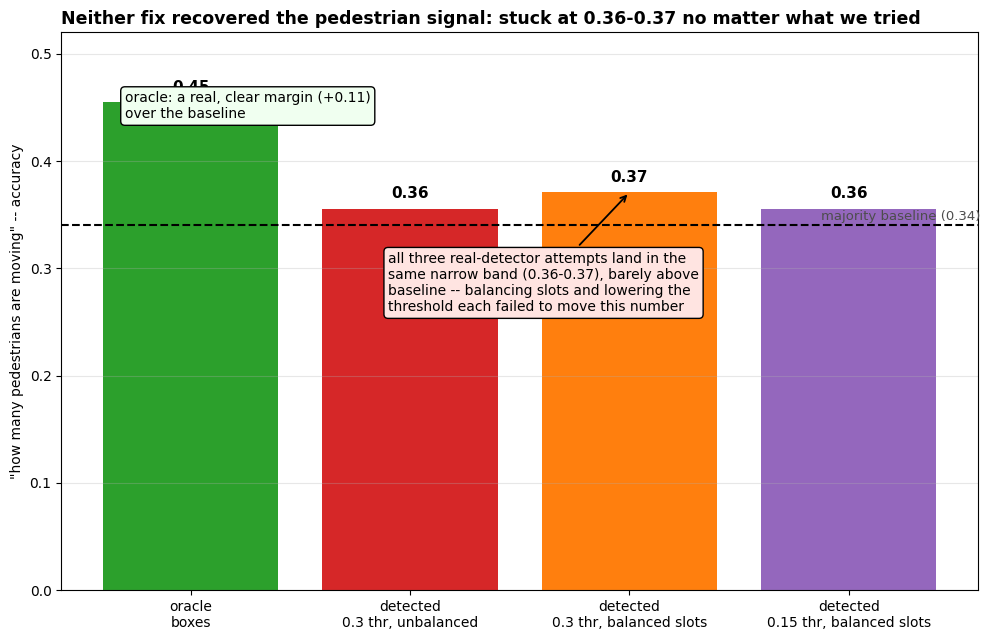

full comparison:
  oracle boxes                        final 0.558 | gap +0.075 | car 0.37 | ped 0.45 | speed 0.73
  detected 0.3 thr, unbalanced        final 0.542 | gap +0.043 | car 0.37 | ped 0.36 | speed 0.72
  detected 0.3 thr, balanced slots    final 0.519 | gap +0.039 | car 0.35 | ped 0.37 | speed 0.68
  detected 0.15 thr, balanced slots   final 0.546 | gap +0.049 | car 0.36 | ped 0.36 | speed 0.69


In [3]:
configs = ["radar_obj_trainval_motionqa", "radar_obj_trainval_motionqa_det",
           "radar_obj_trainval_motionqa_det_balanced", "radar_obj_trainval_motionqa_det2"]
clabels = ["oracle\nboxes", "detected\n0.3 thr, unbalanced", "detected\n0.3 thr, balanced slots", "detected\n0.15 thr, balanced slots"]
ccolors = ["tab:green", "tab:red", "tab:orange", "tab:purple"]

fig, ax = plt.subplots(figsize=(10, 6.5))
vals = [R[n]["per_type"]["moving_count_pedestrian"] for n in configs]
bars = ax.bar(range(4), vals, color=ccolors)
for i, v in enumerate(vals):
    ax.text(i, v + 0.01, f"{v:.2f}", ha="center", fontsize=11, fontweight="bold")
ax.axhline(MAJ["moving_count_pedestrian"], color="k", ls="--", lw=1.5)
ax.text(3.6, MAJ["moving_count_pedestrian"] + 0.005, "majority baseline (0.34)", fontsize=9.5, ha="right", color="0.3")
ax.set_xticks(range(4)); ax.set_xticklabels(clabels, fontsize=10)
ax.set_ylabel("\"how many pedestrians are moving\" -- accuracy")
ax.set_ylim(0, 0.52)
ax.set_title("Neither fix recovered the pedestrian signal: stuck at 0.36-0.37 no matter what we tried", fontsize=12.5, fontweight="bold", loc="left")
ax.grid(alpha=0.3, axis="y")
ax.annotate("oracle: a real, clear margin (+0.11)\nover the baseline",
            xy=(0, vals[0]), xytext=(-0.3, 0.44), fontsize=10, bbox=dict(boxstyle="round", fc="honeydew", ec="k"), arrowprops=dict(arrowstyle="->", lw=1.3))
ax.annotate("all three real-detector attempts land in the\nsame narrow band (0.36-0.37), barely above\nbaseline -- balancing slots and lowering the\nthreshold each failed to move this number",
            xy=(2, vals[2]), xytext=(0.9, 0.26), fontsize=10, bbox=dict(boxstyle="round", fc="mistyrose", ec="k"), arrowprops=dict(arrowstyle="->", lw=1.3))
plt.tight_layout()
plt.show()

print("full comparison:")
for n, l in zip(configs, clabels):
    row = R[n]
    gap = row["val_acc"] - row.get("val_acc_shuffled_radar", float("nan"))
    print(f"  {l.replace(chr(10),' '):35s} final {row['val_acc']:.3f} | gap {gap:+.3f} | "
          f"car {row['per_type']['moving_count_car']:.2f} | ped {row['per_type']['moving_count_pedestrian']:.2f} | speed {row['per_type']['top_speed_car']:.2f}")

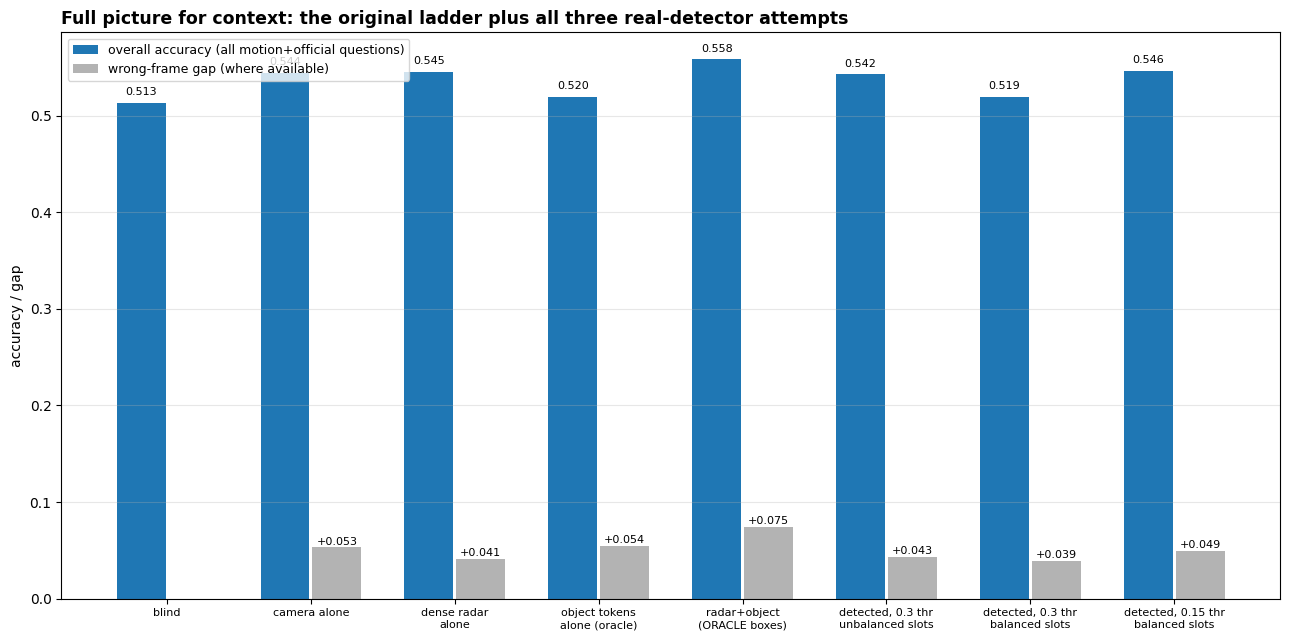

In [4]:
all_names = NAMES
fig, ax = plt.subplots(figsize=(13, 6.5))
accs = [R[n]["val_acc"] for n in all_names]
gaps = [R[n]["val_acc"] - R[n].get("val_acc_shuffled_radar", R[n]["val_acc"]) if "val_acc_shuffled_radar" in R[n] else 0 for n in all_names]
x = np.arange(len(all_names))
ax.bar(x - 0.18, accs, 0.34, color="tab:blue", label="overall accuracy (all motion+official questions)")
ax.bar(x + 0.18, gaps, 0.34, color="0.7", label="wrong-frame gap (where available)")
for xi, v in zip(x - 0.18, accs):
    ax.text(xi, v + 0.008, f"{v:.3f}", ha="center", fontsize=8, rotation=0)
for xi, v, n in zip(x + 0.18, gaps, all_names):
    if "val_acc_shuffled_radar" in R[n]:
        ax.text(xi, v + 0.003, f"{v:+.3f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([LABELS[n] for n in all_names], fontsize=8)
ax.set_ylabel("accuracy / gap")
ax.set_title("Full picture for context: the original ladder plus all three real-detector attempts", fontsize=12.5, fontweight="bold", loc="left")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

## Summary: what this means for the paper

**The honest finding: two plausible, cheap fixes were tried, and neither recovered the pedestrian-counting
result.** Balancing object-token slots by class (so cars can't crowd out pedestrians) made things slightly worse
on every metric except pedestrian-counting, which barely moved (0.36 -> 0.37). Lowering the detection threshold to
catch more real pedestrians also left pedestrian-counting essentially flat (0.36), because the recall gain came
bundled with a collapse in precision -- the model has no way to tell a confident detection from a desperate guess,
since the object token currently carries no confidence score at all.

**What this rules out, and what it doesn't:** it rules out "this is just a slot-allocation bug" and "this is just
a threshold that needs nudging." It does not rule out the underlying idea -- car-counting and speed-judgment held
up close to their oracle-boxes level throughout all three real-detector attempts, so the model clearly *can* use
detected object tokens productively when the detector is good enough (cars) or the signal is more forgiving
(speed). Pedestrians specifically remain blocked by detector quality, in a way that a confidence-aware token or a
genuinely better pedestrian detector would address but a decode-time threshold tweak cannot.

**For the paper, the honest claim right now is therefore narrower than before**: radar's contribution is clear
and robust for car motion and speed judgment, even against real detector noise. The pedestrian-specific claim,
which was the single cleanest piece of evidence for the "radar-led" thesis, remains proven only under oracle
conditions and not yet under realistic ones -- an open question, not a settled one.

**What's still on the table, deliberately not attempted tonight (each is either a real architecture change or a
bigger compute commitment, better done with review rather than fully unattended):**
- Add the detection confidence score as an explicit token feature, so the model can learn to trust a strong
  detection more than a weak one.
- Retrain the detector itself for longer, with a real precision-recall sweep instead of a guessed threshold.
- Repeat the key comparisons across multiple seeds to get real confidence intervals on these numbers.